In [1]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
from tensorflow.keras.optimizers import Adam
import keras
from keras.models import Sequential, Model
from keras.layers import *
from keras.utils import Sequence
from keras.layers import Conv2D, MaxPooling2D, Conv2DTranspose
from qkeras import *

from keras.utils import Sequence
from keras.callbacks import CSVLogger
from keras.callbacks import EarlyStopping
from keras.losses import MeanSquaredError

import os
import random
from datetime import datetime
import time

import matplotlib.pyplot as plt

pi = 3.14159265359

maxval=1e9
minval=1e-9

2026-06-24 14:13:16.627818: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import importlib
import DAE_DataGenerator

importlib.reload(DAE_DataGenerator)
from DAE_DataGenerator import OptimizedDataGenerator as DAE_optDG
#from dataprep import *
from OptimizedDataGenerator_v2 import OptimizedDataGenerator
from loss import *
from dataset_utils import add_noise
import math


In [5]:
'''For Categorical SQuatoEncoder'''
from SoftQuantizeLayer import SoftQuantizeLayer

def encoder_network(shape, var, kernel_size=3, n_filters=5, pool_size=2):
    var = QSeparableConv2D(
        n_filters, kernel_size, padding = 'same',
    )(var)
    var = QActivation("quantized_tanh(4, 0, 1)")(var)
    var = AveragePooling2D(
        pool_size=(pool_size, pool_size), 
        strides=pool_size, 
        padding="same", 
        data_format='channels_last',
    )(var)
    var = QActivation("quantized_tanh(4, 0, 1)")(var)
    var = QConv2D(
        n_filters,kernel_size, padding = 'same',
    )(var)
    var = QActivation("quantized_tanh(4, 0, 1)")(var)  
    var = AveragePooling2D(
        pool_size=(pool_size, pool_size), 
        strides=pool_size, 
        padding="same", 
        data_format='channels_last',
    )(var)
    var = QActivation("quantized_tanh(4, 0, 1)")(var)  
    return var

def Qdecoder_network(shape, var, kernel_size=3, n_filters=5, pool_size=2):
    var = Conv2DTranspose(
        n_filters, 1, padding = 'same', strides = pool_size,
    )(var)
    var = QActivation("quantized_tanh(16, 0, 1)")(var)
    var = Conv2DTranspose(
        n_filters, kernel_size,
        strides = pool_size,
        padding="same",
    )(var)
    var = QActivation("quantized_tanh(16, 0, 1)")(var)    
    var = Conv2D(shape[-1], (pool_size, pool_size), padding="same")(var)
    var = QActivation("quantized_tanh(16, 0, 1)")(var)
    var = Flatten()(var)
    var = Dense(math.prod(shape)*4, activation='softmax')(var)
    var = Reshape((*shape, 4))(var)
    return var

def CreateSQAutoEncoder(shape, n_filters=5, pool_size=2, conv_kernel_size=3, decoder_filters = 5, mean_filter=False, thresh = False, xrange = [-1,1], log_standardize=True):
    x_base = x_in = Input(shape)
    x_base = SoftQuantizeLayer(
        n_bits=2,
        initial_thresholds = [247.80, 668.41, 1662.85],
        # initial_thresholds = [0,240, 400],

        # initial_levels = [0.0, 0.33333, 0.66667, 1.0],
        initial_levels = [0.0, 1.0, 2.0, 3.0],
        threshold_offset = 0,
        # initial_range=[-1.0, 1.0],
        trainable_levels=False,
        trainable_thresholds=True,
        initial_k=1.0,
        trainable_k=False,
        name='soft_quantizer_output'
    )(x_base)
    stack = encoder_network(shape, x_base, n_filters=n_filters, pool_size=pool_size, kernel_size = conv_kernel_size)
    stack = Qdecoder_network(shape, stack, n_filters=decoder_filters, pool_size=pool_size, kernel_size = conv_kernel_size)
    # print(type(stack))
    if xrange is not None:
        def scaled_function(data):
            return asymmetric_scaling(data, pos_scale=xrange[1], neg_scale=abs(xrange[0]))
        stack = Lambda(function = scaled_function)(stack)
    model = Model(inputs=x_in, outputs=stack)
    return model

In [13]:
import models
importlib.reload(models)
from models import *
# from models import CreateAutoEncoder, CreateSQAutoEncoder

# weights_path = './SQ_DAE/model-11644ab3-SQDAE_2bit_80eN_CategoricalOutput_lowThreshTarget-checkpoints/'
# weights_path = './SQ_DAE/model-5d8a15ee-SQDAE_Categorical_v2_2bit_80eN_Target_0_30_856-checkpoints/'
# weights_path = './SQ_DAE/model-966a30e9-SQDAE_Categorical_2bit_80eN_Target_0_7_23_134_404_867_1748-checkpoints'
# weights_path = './SQ_DAE/model-e0e43247-SQDAE_Categorical_2bit_240eN_Target_0_30_856-checkpoints'
weights_path = './SQ_DAE/model-65492abf-SQDAE_Categorical_2bit_0eN_Target_0_30_856-checkpoints'
# base_dir = weights_path
# checkpoint_files = [os.path.join(base_dir, f) for f in os.listdir(base_dir) if f.endswith('.hdf5')]
# latest_checkpoint = max(checkpoint_files, key=os.path.getmtime)
# #training_cp_path = os.path.join(base_dir, 'training_log.csv')
# #training_history = pd.read_csv(training_cp_path)

# print(f"Loading model from {latest_checkpoint}")

model = CreateSQAE_MaxReg_fromweights((16,16,2), weights_path, FEBits = 2, OutBits = 2, n_filters=5, pool_size=2, 
                        conv_kernel_size=3, decoder_filters = 128)
model.summary()

model.compile(
    optimizer=tf.keras.optimizers.Nadam(learning_rate=1e-3),
    loss=custom_loss
)


Loading model from ./SQ_DAE/model-65492abf-SQDAE_Categorical_2bit_0eN_Target_0_30_856-checkpoints/weights.1777-t113535.8125-v116516.2422.hdf5
latent space layer:  q_activation_12 (None, 4, 4, 5)
Model: "model_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 16, 16, 2)]       0         
                                                                 
 soft_quantizer_output (Soft  (None, 16, 16, 2)        4         
 QuantizeLayer)                                                  
                                                                 
 q_separable_conv2d_1 (QSepa  (None, 16, 16, 5)        33        
 rableConv2D)                                                    
                                                                 
 q_activation_9 (QActivation  (None, 16, 16, 5)        0         
 )                                                            

In [6]:
'''Load weights and extract the encoder'''

import models
importlib.reload(models)
from models import *
# from models import CreateAutoEncoder, CreateSQAutoEncoder

# weights_path = './SQ_DAE/model-11644ab3-SQDAE_2bit_80eN_CategoricalOutput_lowThreshTarget-checkpoints/'
# weights_path = './SQ_DAE/model-5d8a15ee-SQDAE_Categorical_v2_2bit_80eN_Target_0_30_856-checkpoints/'
# weights_path = './SQ_DAE/model-966a30e9-SQDAE_Categorical_2bit_80eN_Target_0_7_23_134_404_867_1748-checkpoints'
# weights_path = './SQ_DAE/model-e0e43247-SQDAE_Categorical_2bit_240eN_Target_0_30_856-checkpoints'
weights_path = './SQ_DAE/model-65492abf-SQDAE_Categorical_2bit_0eN_Target_0_30_856-checkpoints'
base_dir = weights_path
checkpoint_files = [os.path.join(base_dir, f) for f in os.listdir(base_dir) if f.endswith('.hdf5')]
latest_checkpoint = max(checkpoint_files, key=os.path.getmtime)
#training_cp_path = os.path.join(base_dir, 'training_log.csv')
#training_history = pd.read_csv(training_cp_path)

print(f"Loading model from {latest_checkpoint}")
# DAE=CreateAutoEncoder((16,16,2), n_filters=5, pool_size=2, conv_kernel_size = 3, decoder_filters = 64)
DAE=CreateSQAutoEncoder((16,16,2), n_filters=5, pool_size=2, conv_kernel_size = 3, 
                        decoder_filters = 128, xrange = None)

DAE.load_weights(latest_checkpoint)
model_summary = [[layer.name, layer.output.shape] for layer in DAE.layers]

for i, layer in enumerate(DAE.layers):
    print('index:', i, layer.name)


layer_name = DAE.layers[9].name 
# print(layer_name)
encoder = Model(inputs=DAE.input, outputs=DAE.get_layer(layer_name).output)
encoder.trainable = False
encoder.summary()

# encoder = DAE.get_layer(layer_name)

print(encoder.output.shape)




Loading model from ./SQ_DAE/model-e0e43247-SQDAE_Categorical_2bit_240eN_Target_0_30_856-checkpoints/weights.33-t203269.0938-v205666.7656.hdf5
index: 0 input_2
index: 1 soft_quantizer_output
index: 2 q_separable_conv2d_1
index: 3 q_activation_7
index: 4 average_pooling2d_2
index: 5 q_activation_8
index: 6 q_conv2d_1
index: 7 q_activation_9
index: 8 average_pooling2d_3
index: 9 q_activation_10
index: 10 conv2d_transpose_2
index: 11 q_activation_11
index: 12 conv2d_transpose_3
index: 13 q_activation_12
index: 14 conv2d_1
index: 15 q_activation_13
index: 16 flatten_1
index: 17 dense_1
index: 18 reshape_1
Model: "model_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 16, 16, 2)]       0         
                                                                 
 soft_quantizer_output (Soft  (None, 16, 16, 2)        4         
 QuantizeLayer)                              

In [7]:
'''attach a dense regression network to the latent space'''
from models import var_network

x_in = encoder.input
lat_shape = encoder.output.shape
dense = var_network(encoder.output, hidden=16, output=14)
model = Model(inputs=x_in, outputs=dense)

model.summary()

model.compile(
    optimizer=tf.keras.optimizers.Nadam(learning_rate=1e-3),
    loss=custom_loss
)


Model: "model_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 16, 16, 2)]       0         
                                                                 
 soft_quantizer_output (Soft  (None, 16, 16, 2)        4         
 QuantizeLayer)                                                  
                                                                 
 q_separable_conv2d_1 (QSepa  (None, 16, 16, 5)        33        
 rableConv2D)                                                    
                                                                 
 q_activation_7 (QActivation  (None, 16, 16, 5)        0         
 )                                                               
                                                                 
 average_pooling2d_2 (Averag  (None, 8, 8, 5)          0         
 ePooling2D)                                               

In [6]:
dataset_base_dir = "/uscms/home/bweiss/nobackup/smart-pixels/"
tfrecords_base_dir = os.path.join(dataset_base_dir, "tfrecords")

# dataset_dir_train = os.path.join(dataset_base_dir, "dataset_3sr_16x16_50x12P5_parquets", 'train/')
# dataset_dir_val = os.path.join(dataset_base_dir, "dataset_3sr_16x16_50x12P5_parquets", 'test/')

dataset_dir_train = os.path.join(dataset_base_dir, "dataset_3sr_16x16_50x12P5_centeredIncidence_parquets", 'train_contained/')
dataset_dir_val = os.path.join(dataset_base_dir, "dataset_3sr_16x16_50x12P5_centeredIncidence_parquets", 'test_contained/')


# tfrecords_dir_train = os.path.join(tfrecords_base_dir, "TFR_train", '3sr_16x16_80eN_raw')
# tfrecords_dir_val   = os.path.join(tfrecords_base_dir, "TFR_val", '3sr_16x16_80eN_raw')

tfrecords_dir_train = os.path.join(tfrecords_base_dir, "TFR_train", '3srCI_16x16_0eN_raw')
tfrecords_dir_val   = os.path.join(tfrecords_base_dir, "TFR_val", '3srCI_16x16_0eN_raw')

print(dataset_dir_val)
batch_size = 5000
val_batch_size = 5000
train_file_size = 80
val_file_size = 20

/uscms/home/bweiss/nobackup/smart-pixels/dataset_3sr_16x16_50x12P5_centeredIncidence_parquets/test_contained/


In [7]:
'''CHANGE THRESHOLDS AND TO_STANDARDIZE!!'''
start_time = time.time()
validation_generator = OptimizedDataGenerator(
    dataset_base_dir = dataset_dir_val,
    file_type = "parquet",
    data_format = "3D",
    batch_size = val_batch_size,
    # optimize_batch_size = True,
    file_count = val_file_size,
    to_standardize= False,
    select_contained = True,
    log_compression = False,
    noise = -1, #[0,240], #[mean, sigma]
    min_threshold = None,
    max_threshold = None,
    
    labels_list = ['x-midplane','y-midplane','cotAlpha','cotBeta'],
    input_shape = (2,16,16), # (20,13,21),
    transpose = (0,2,3,1),
    shuffle = False, 
    files_from_end=True,

    tfrecords_dir = tfrecords_dir_val,
    use_time_stamps = [0,19],
    max_workers = 2
)
print("--- Validation generator %s seconds ---" % (time.time() - start_time))

# training generator
start_time = time.time()
training_generator = OptimizedDataGenerator(
    dataset_base_dir = dataset_dir_train,
    file_type = "parquet",
    data_format = "3D",
    batch_size = batch_size,
    log_compression = False,
    # optimize_batch_size = True,
    file_count = train_file_size,
    to_standardize= False,
    select_contained = True,
    labels_list = ['x-midplane','y-midplane','cotAlpha','cotBeta'],
    input_shape = (2,16,16), # (20,13,21),
    transpose = (0,2,3,1),
    shuffle = False, # True 
    noise = -1, #[0,240],
    # threshold = -1,
    tfrecords_dir = tfrecords_dir_train,
    use_time_stamps = [0,19],
    max_workers = 2
)

print("--- Training generator %s seconds ---" % (time.time() - start_time))

Processing Files...: 100%|██████████| 20/20 [00:04<00:00,  4.48it/s]


Directory /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/3srCI_16x16_0eN_raw does not exist and cannot be removed.


Saving batches as TFRecords: 100%|██████████| 21/21 [00:10<00:00,  2.09it/s]


Metadata saved successfully ast /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/3srCI_16x16_0eN_raw/metadata.json
Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/3srCI_16x16_0eN_raw/metadata.json
--- Validation generator 16.280619621276855 seconds ---


Processing Files...: 100%|██████████| 80/80 [00:16<00:00,  4.89it/s]


Directory /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/3srCI_16x16_0eN_raw does not exist and cannot be removed.


Saving batches as TFRecords: 100%|██████████| 84/84 [00:38<00:00,  2.17it/s]


Metadata saved successfully ast /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/3srCI_16x16_0eN_raw/metadata.json
Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/3srCI_16x16_0eN_raw/metadata.json


--- Training generator 55.817670822143555 seconds ---


In [8]:
# Loading pre-generated TFRecords
validation_generator = OptimizedDataGenerator(
    load_from_tfrecords_dir= tfrecords_dir_val,
    shuffle=False,
    seed=42,
    quantize=False,
)

training_generator = OptimizedDataGenerator(
    load_from_tfrecords_dir = tfrecords_dir_train,
    shuffle=False,
    seed=42,
    quantize=False,
)

Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/3srCI_16x16_0eN_raw/metadata.json


Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/3srCI_16x16_0eN_raw/metadata.json


tf.Tensor([ 0.30724844 -0.2138076  -0.787956   -0.2616194 ], shape=(4,), dtype=float32)
max: 24162.4
min: -3385.5


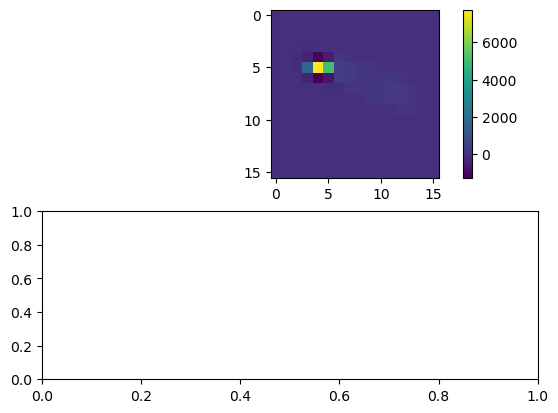

In [9]:
import matplotlib.pyplot as plt
from matplotlib import colors

n=90

cluster = training_generator[0]
# print(np.max(cluster[0].numpy()))
print(cluster[1][n])
cluster=cluster[0][:,:,:,0]

print('max:', np.max(cluster.numpy()))
print('min:', np.min(cluster.numpy()))

fig,ax = plt.subplots(2,1)
h = ax[0].imshow(cluster[n])
fig.colorbar(h)

In [10]:
from datetime import datetime
tname = 'SQDAE_Maxregression_Categorical2bit_0eN_Target_0_30_856'
fingerprint = '%08x' % random.randrange(16**8)
timestamp = datetime.now().strftime('%Y%m%d-%H%M%S')
os.makedirs("trained_models", exist_ok=True)
base_dir = f'./SQ_DAE_regression/model-{fingerprint}-{tname}-checkpoints'
os.makedirs(base_dir, exist_ok=True)  
checkpoint_filepath = base_dir + '/weights.{epoch:02d}-t{loss:.2f}-v{val_loss:.2f}.hdf5'
print(fingerprint)

00d39d23


In [11]:
from tensorflow.keras.callbacks import CSVLogger, EarlyStopping, ModelCheckpoint, Callback

early_stopping_patience = 500

class CustomModelCheckpoint(ModelCheckpoint):
    def on_epoch_end(self, epoch, logs=None):
        super().on_epoch_end(epoch, logs)
        checkpoints = [f for f in os.listdir(base_dir) if f.startswith('weights')]
        if len(checkpoints) > 1:
            checkpoints.sort(key=lambda x: os.path.getmtime(os.path.join(base_dir,x)))
            for checkpoint in checkpoints[:-1]:
                os.remove(os.path.join(base_dir, checkpoint))

es = EarlyStopping(patience=early_stopping_patience, restore_best_weights=True)

mcp = CustomModelCheckpoint(
    filepath=checkpoint_filepath,
    save_weights_only=True,
    monitor='val_loss',
    save_best_only=True,
    save_freq='epoch',
    verbose=1
)

csv_logger = CSVLogger(f'{base_dir}/training_log.csv', append=True)

In [14]:
history = model.fit(
        x=training_generator,
        validation_data=validation_generator,
        callbacks=[es, mcp, csv_logger],
        epochs=2000,
        shuffle=False,
        verbose=1
    )

Epoch 1/2000


2026-06-24 14:29:17.014315: I tensorflow/stream_executor/cuda/cuda_blas.cc:1614] TensorFloat-32 will be used for the matrix multiplication. This will only be logged once.
2026-06-24 14:29:17.023840: I tensorflow/stream_executor/cuda/cuda_dnn.cc:384] Loaded cuDNN version 8800


 1/84 [..............................] - ETA: 3:14 - loss: 103563.8828

2026-06-24 14:29:17.307285: I tensorflow/core/util/cuda_solvers.cc:179] Creating GpuSolver handles for stream 0x564f74662560


84/84 [==============================] - ETA: 0s - loss: 61745.3203
Epoch 1: val_loss improved from inf to 24077.44336, saving model to ./SQ_DAE_regression/model-00d39d23-SQDAE_Maxregression_Categorical2bit_0eN_Target_0_30_856-checkpoints/weights.01-t61745.32-v24077.44.hdf5
84/84 [==============================] - 13s 123ms/step - loss: 61745.3203 - val_loss: 24077.4434
Epoch 2/2000
84/84 [==============================] - ETA: 0s - loss: 18757.2539
Epoch 2: val_loss improved from 24077.44336 to 13804.02246, saving model to ./SQ_DAE_regression/model-00d39d23-SQDAE_Maxregression_Categorical2bit_0eN_Target_0_30_856-checkpoints/weights.02-t18757.25-v13804.02.hdf5
84/84 [==============================] - 8s 91ms/step - loss: 18757.2539 - val_loss: 13804.0225
Epoch 3/2000
84/84 [==============================] - ETA: 0s - loss: 10519.5020
Epoch 3: val_loss improved from 13804.02246 to 7493.32324, saving model to ./SQ_DAE_regression/model-00d39d23-SQDAE_Maxregression_Categorical2bit_0eN_Targ

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



84/84 [==============================] - ETA: 0s - loss: -28052.3320
Epoch 1734: val_loss did not improve from -29562.74023
84/84 [==============================] - 9s 105ms/step - loss: -28052.3320 - val_loss: -28130.1289
Epoch 1735/2000
84/84 [==============================] - ETA: 0s - loss: -27685.9844
Epoch 1735: val_loss did not improve from -29562.74023
84/84 [==============================] - 8s 98ms/step - loss: -27685.9844 - val_loss: -27505.1895
Epoch 1736/2000
84/84 [==============================] - ETA: 0s - loss: -28522.1797
Epoch 1736: val_loss did not improve from -29562.74023
84/84 [==============================] - 8s 91ms/step - loss: -28522.1797 - val_loss: -26184.1152
Epoch 1737/2000
84/84 [==============================] - ETA: 0s - loss: -28047.3516
Epoch 1737: val_loss did not improve from -29562.74023
84/84 [==============================] - 8s 90ms/step - loss: -28047.3516 - val_loss: -28627.8613
Epoch 1738/2000
84/84 [==============================] - ETA: 0

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)

